# PlantSeg Stage 1 — Session 2: Train Models 5–8

Trains the remaining 4 models and saves their `result_*.pkl` files:
5. **ConvNeXtV2Tiny**
6. **ViTBase16**
7. **SwinTiny**
8. **GatedFusionLight**

**Output:** `result_ConvNeXtV2Tiny.pkl`, `result_ViTBase16.pkl`, `result_SwinTiny.pkl`, `result_GatedFusionLight.pkl`  
saved to `/kaggle/working/s1_results/`

> After this session ends, **collect all 8 `.pkl` files** (4 from Session 1 + 4 from this session)  
> and upload them as a Kaggle dataset. Then run **Session 3** (the Aggregator).

> **Kaggle note:** Internet **ON** required for `timm` pretrained weights.  
> Lower `IMG_SIZE_CNN` to `320` or `256` if you hit GPU OOM.

## Section 1 — Install Dependencies & Imports

Installs `timm`, `imagehash`, `statsmodels`, and `grad-cam`, then imports all required libraries and sets a global random seed for reproducibility.

In [1]:
!pip install -q timm imagehash statsmodels grad-cam
import os, json, math, time, random, warnings, pickle
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision; from torchvision import transforms
import timm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, matthews_corrcoef, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, auc)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="talk")
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("Device:", device)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 57.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 100.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is inc

## Section 2 — Global Configuration

Set `DATA_ROOT` to the PlantSeg dataset mount and `OUTDIR` to the output directory.
All 8 models share the same hyperparameters defined here. Change `MODELS_TO_TRAIN`
to run a subset, or set `QUICK_SMOKE = True` for a fast sanity-check (1 epoch,
8 images per class).


In [2]:
# ============ CONFIG ============
# Edit DATA_ROOT to point at your PlantSeg dataset mount
DATA_ROOT = Path("/kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg")
if not (DATA_ROOT/"Metadata.csv").exists():
    for cand in [Path("/kaggle/input/plantseg"), Path("plantseg"), Path(".")]:
        if (cand/"Metadata.csv").exists(): DATA_ROOT=cand; break
assert (DATA_ROOT/"Metadata.csv").exists(), f"Metadata.csv not found under {DATA_ROOT} — edit DATA_ROOT."

OUTDIR = Path("/kaggle/working/s1_results"); FIG = OUTDIR/"figures"
OUTDIR.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# List of all 8 models to train sequentially.
# Remove any name from this list to skip it.
MODELS_TO_TRAIN = [
    "MobileNetV3Large",  # Trainer 1/8
    "EfficientNetB0",    # Trainer 2/8
    "ResNet50",          # Trainer 3/8
    "EfficientNetV2S",   # Trainer 4/8
    "ConvNeXtV2Tiny",    # Trainer 5/8
    "ViTBase16",         # Trainer 6/8 — transformer
    "SwinTiny",          # Trainer 7/8 — transformer
    "GatedFusionLight",  # Trainer 8/8 — dual-branch fusion
]

SCOPE = "full"   # "full" = all plants | "fruit" = fruit hosts only
FRUIT_HOSTS = {"Apple","Citrus","Grape","Banana","Peach","Blueberry",
               "Plum","Cherry","Raspberry","Strawberry"}

NUM_EPOCHS      = 40
PATIENCE        = 8
LR              = 3e-4
WEIGHT_DECAY    = 1e-4
USE_PRETRAINED  = True
USE_CLASS_WEIGHTS = True
LABEL_SMOOTHING = 0.05
IMG_SIZE_CNN    = 384   # lower to 320 or 256 if OOM
USE_RANDAUG     = True
USE_TTA         = True
QUICK_SMOKE     = False  # True → 1 epoch, 8 imgs/class (fast sanity check)

print("DATA_ROOT:", DATA_ROOT)
print("Models to train:", MODELS_TO_TRAIN)


DATA_ROOT: /kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg
Models to train: ['MobileNetV3Large', 'EfficientNetB0', 'ResNet50', 'EfficientNetV2S', 'ConvNeXtV2Tiny', 'ViTBase16', 'SwinTiny', 'GatedFusionLight']


## Section 3 — Dataset Index & Class Weights

Reads `Metadata.csv`, resolves image paths, filters to `SCOPE`, and computes
inverse-frequency class weights used in the cross-entropy loss.
Prints split sizes and number of disease classes.


In [3]:
# ============ DATA INDEX ============
meta = pd.read_csv(DATA_ROOT/"Metadata.csv", encoding="utf-8-sig")
meta["split"] = meta["Split"].map({"Training":"train","Validation":"val","Test":"test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT/"images"/r["split"]/r["Name"], axis=1)
meta["label"] = meta["Disease"]; meta["plant"] = meta["Plant"]
if SCOPE == "fruit":
    meta = meta[meta["plant"].isin(FRUIT_HOSTS)].reset_index(drop=True)
meta = meta[meta["filepath"].apply(lambda p: Path(p).exists())].reset_index(drop=True)

CLASS_NAMES = sorted(meta["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
label2idx = {c: i for i, c in enumerate(CLASS_NAMES)}

train_df = meta[meta.split=="train"].reset_index(drop=True)
val_df   = meta[meta.split=="val"].reset_index(drop=True)
test_df  = meta[meta.split=="test"].reset_index(drop=True)

if QUICK_SMOKE:
    train_df = train_df.groupby("label",group_keys=False).head(8).reset_index(drop=True)
    val_df   = val_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    test_df  = test_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    NUM_EPOCHS = 1

counts = train_df["label"].map(label2idx).value_counts().reindex(range(NUM_CLASSES)).fillna(0)
inv = np.where(counts.values > 0, 1.0/counts.values, 0.0)
cw  = inv / inv[inv>0].mean()
class_weights = torch.tensor(cw, dtype=torch.float32, device=device)

print(f"classes={NUM_CLASSES}  train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")


classes=115  train=5367  val=846  test=1561


## Section 4 — Transforms & Dataset Class

`make_transforms(sz)` returns a pair of `(train_transform, eval_transform)`.
Training uses `RandAugment` + `RandomErasing` when `USE_RANDAUG=True`, otherwise
falls back to rotation and colour-jitter.  
`DS` is a lightweight `torch.utils.data.Dataset` wrapper over the metadata DataFrame.


In [4]:
# ============ TRANSFORMS / DATASET ============
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]

def make_transforms(sz):
    ops = [transforms.RandomResizedCrop(sz, scale=(0.7,1.0)),
           transforms.RandomHorizontalFlip(),
           transforms.RandomVerticalFlip(p=0.2)]
    if USE_RANDAUG:
        ops += [transforms.RandAugment(num_ops=2, magnitude=9)]
    else:
        ops += [transforms.RandomRotation(15),
                transforms.ColorJitter(0.2, 0.2, 0.2, 0.05)]
    ops += [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    if USE_RANDAUG:
        ops += [transforms.RandomErasing(p=0.25)]
    ev = transforms.Compose([transforms.Resize((sz,sz)),
                             transforms.ToTensor(),
                             transforms.Normalize(MEAN, STD)])
    return transforms.Compose(ops), ev

class DS(Dataset):
    def __init__(self, d, t):
        self.df = d.reset_index(drop=True); self.t = t
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.t(Image.open(r.filepath).convert("RGB")), label2idx[r.label]


## Section 5 — Model Zoo

`build_backbone(name, num_classes)` returns a `(model, img_size, batch_size)` tuple
for the 7 single-backbone architectures.  
`GatedFusionLightModel` is the custom dual-branch fusion model: it fuses
**MobileNetV3Large** and **EfficientNetB0** features through a learned soft-gate
before the final classifier.


In [5]:
# ============ MODEL ZOO ============
def build_backbone(name, num_classes, pretrained=USE_PRETRAINED):
    if name == "MobileNetV3Large":
        m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V2" if pretrained else None)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
        return m, IMG_SIZE_CNN, 24
    if name == "EfficientNetB0":
        return timm.create_model("efficientnet_b0", pretrained=pretrained, num_classes=num_classes), IMG_SIZE_CNN, 24
    if name == "ResNet50":
        m = torchvision.models.resnet50(weights="IMAGENET1K_V2" if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m, IMG_SIZE_CNN, 16
    if name == "EfficientNetV2S":
        return timm.create_model("tf_efficientnetv2_s", pretrained=pretrained, num_classes=num_classes), IMG_SIZE_CNN, 12
    if name == "ConvNeXtV2Tiny":
        return timm.create_model("convnextv2_tiny", pretrained=pretrained, num_classes=num_classes), IMG_SIZE_CNN, 16
    if name == "ViTBase16":
        return timm.create_model("vit_base_patch16_224", pretrained=pretrained, num_classes=num_classes), 224, 16
    if name == "SwinTiny":
        return timm.create_model("swin_tiny_patch4_window7_224", pretrained=pretrained, num_classes=num_classes), 224, 16
    raise ValueError(name)

class _Gated(nn.Module):
    def __init__(self, ba, da, bb, db, nc, gh, hh, dr):
        super().__init__(); self.branch_a=ba; self.branch_b=bb; fused=da+db
        self.gate = nn.Sequential(nn.Linear(fused,gh), nn.ReLU(), nn.Linear(gh,2), nn.Softmax(dim=1))
        self.classifier = nn.Sequential(nn.Linear(fused,hh), nn.ReLU(), nn.Dropout(dr), nn.Linear(hh,nc))
    def forward(self, x):
        fa, fb = self.branch_a(x), self.branch_b(x)
        g = self.gate(torch.cat([fa,fb], 1))
        return self.classifier(torch.cat([fa*g[:,0:1], fb*g[:,1:2]], 1))

def GatedFusionLightModel(nc, pretrained=USE_PRETRAINED):
    mb = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V2" if pretrained else None)
    da = mb.classifier[0].in_features; mb.classifier = nn.Identity()
    b  = timm.create_model("efficientnet_b0", pretrained=pretrained, num_classes=0, global_pool="avg")
    return _Gated(mb, da, b, b.num_features, nc, 128, 256, 0.3)

FUSION_MODELS = {"GatedFusionLight": GatedFusionLightModel}


## Section 6 — Training & Metric Helper Functions

- `train_one(model_name)` — full training loop with AdamW, linear warm-up +
  cosine annealing LR schedule, AMP mixed precision, early stopping, and TTA
  (horizontal-flip) at inference.  
- `compute_metrics(y, yp, ypb, n)` — computes accuracy, balanced accuracy,
  macro/weighted F1, precision, recall, MCC, ROC-AUC, and macro specificity.  
- `deployment(model, img_size)` — counts parameters, measures checkpoint size,
  and benchmarks CPU/GPU latency.


In [6]:
# ============ TRAIN / METRICS HELPERS ============
def train_one(model_name, num_epochs=NUM_EPOCHS, patience=PATIENCE):
    if model_name in FUSION_MODELS:
        model = FUSION_MODELS[model_name](NUM_CLASSES).to(device); img_size, bs = 224, 16
    else:
        model, img_size, bs = build_backbone(model_name, NUM_CLASSES); model = model.to(device)
    ttf, etf = make_transforms(img_size)
    tl = DataLoader(DS(train_df, ttf), batch_size=bs, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
    vl = DataLoader(DS(val_df,   etf), batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
    te = DataLoader(DS(test_df,  etf), batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
    is_tf = model_name in ("ViTBase16","SwinTiny")
    lr = 5e-5 if is_tf else LR; warm_ep = 3 if is_tf else 2; pat = 10 if is_tf else patience
    opt  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    warm = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=warm_ep)
    cos  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, num_epochs-warm_ep))
    sch  = torch.optim.lr_scheduler.SequentialLR(opt, [warm, cos], milestones=[warm_ep])
    crit = nn.CrossEntropyLoss(weight=class_weights if USE_CLASS_WEIGHTS else None, label_smoothing=LABEL_SMOOTHING)
    scaler = torch.cuda.amp.GradScaler(enabled=device.type=="cuda")
    hist = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}; best=-1; best_state=None; bad=0
    for ep in range(num_epochs):
        model.train(); run=cor=tot=0
        for x,y in tl:
            x,y = x.to(device),y.to(device); opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item()*x.size(0); cor += (out.argmax(1)==y).sum().item(); tot += y.size(0)
        trl, tra = run/tot, cor/tot
        model.eval(); vr=vc=vt=0
        with torch.no_grad():
            for x,y in vl:
                x,y = x.to(device),y.to(device); out = model(x); loss = crit(out,y)
                vr += loss.item()*x.size(0); vc += (out.argmax(1)==y).sum().item(); vt += y.size(0)
        vlo, vac = vr/vt, vc/vt; sch.step()
        for k,v in zip(hist, [trl,vlo,tra,vac]): hist[k].append(v)
        print(f"[{model_name}] ep{ep+1}/{num_epochs} lr={opt.param_groups[0]['lr']:.1e} "
              f"trL={trl:.3f} vL={vlo:.3f} trA={tra:.3f} vA={vac:.3f}")
        if vac > best+1e-4:
            best=vac; best_state={k:v.cpu().clone() for k,v in model.state_dict().items()}; bad=0
        else:
            bad += 1
            if ep >= warm_ep and bad >= pat:
                print(f"  early stop @ ep{ep+1}"); break
    model.load_state_dict(best_state); torch.save(best_state, OUTDIR/f"{model_name}_best.pt")
    model.eval(); P=[]; Y=[]; PR=[]
    with torch.no_grad():
        for x,y in te:
            x = x.to(device); lg = model(x)
            if USE_TTA: lg = lg + model(torch.flip(x, dims=[3]))
            p = F.softmax(lg, 1).cpu().numpy(); P.extend(p.argmax(1)); Y.extend(y.numpy()); PR.extend(p)
    return model, img_size, hist, np.array(Y), np.array(P), np.array(PR)

def deployment(model, img_size, nw=5, ni=30):
    n = sum(p.numel() for p in model.parameters())
    tmp = OUTDIR/"_t.pt"; torch.save(model.state_dict(), tmp)
    sz = os.path.getsize(tmp)/1e6; os.remove(tmp)
    d  = torch.randn(1, 3, img_size, img_size)
    def t(dev):
        m = model.to(dev).eval(); dd = d.to(dev)
        with torch.no_grad():
            for _ in range(nw): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            t0 = time.time()
            for _ in range(ni): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            return (time.time()-t0)/ni*1000
    lg = t(device) if device.type=="cuda" else float("nan")
    lc = t(torch.device("cpu")); model.to(device)
    return {"params_M": n/1e6, "checkpoint_size_MB": sz, "latency_cpu_ms": lc, "latency_gpu_ms": lg}

def compute_metrics(y, yp, ypb, n):
    cm = confusion_matrix(y, yp, labels=range(n)); specs=[]
    for i in range(n):
        tn = cm.sum()-cm[i,:].sum()-cm[:,i].sum()+cm[i,i]; fp = cm[:,i].sum()-cm[i,i]
        specs.append(tn/(tn+fp) if (tn+fp)>0 else float("nan"))
    present = [c for c in range(n) if (y==c).sum()>0]; aucs=[]
    for c in present:
        try: aucs.append(roc_auc_score((y==c).astype(int), ypb[:,c]))
        except Exception: pass
    return {"accuracy": accuracy_score(y,yp),
            "balanced_accuracy": balanced_accuracy_score(y,yp),
            "f1_macro": f1_score(y,yp,average="macro"),
            "f1_weighted": f1_score(y,yp,average="weighted"),
            "precision_macro": precision_score(y,yp,average="macro",zero_division=0),
            "recall_macro": recall_score(y,yp,average="macro",zero_division=0),
            "mcc": matthews_corrcoef(y,yp),
            "roc_auc_macro": float(np.mean(aucs)) if aucs else float("nan"),
            "macro_specificity": float(np.nanmean(specs))}, cm


## Section 7 — Per-Model Figure Helper

`plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size)` draws and saves three
inline plots for each trained model:
1. **Loss & accuracy curves** across epochs  
2. **Row-normalised confusion matrix** heat-map  
3. **Micro + macro ROC curve**


In [7]:
# ============ PER-MODEL FIGURE HELPER ============
def plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size):
    ep = range(1, len(hist["train_loss"])+1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="val")
    ax[0].set_title(f"{MODEL_NAME} — loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(ep, hist["train_acc"],  label="train"); ax[1].plot(ep, hist["val_acc"],  label="val")
    ax[1].set_title(f"{MODEL_NAME} — accuracy"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_loss_acc.png", dpi=200, bbox_inches="tight"); plt.show()

    cm = confusion_matrix(Y, P, labels=range(NUM_CLASSES))
    cmn = cm.astype(float)/cm.astype(float).sum(1, keepdims=True).clip(min=1)
    s = max(7, NUM_CLASSES*0.16)
    plt.figure(figsize=(s,s))
    sns.heatmap(cmn, cmap="viridis", square=True, cbar_kws={"shrink":0.5},
                xticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False,
                yticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False)
    plt.title(f"{MODEL_NAME} — confusion (row-norm)"); plt.xlabel("predicted"); plt.ylabel("true")
    plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

    y_oh = np.eye(NUM_CLASSES)[Y]; fpr,tpr,_ = roc_curve(y_oh.ravel(), PR.ravel()); micro = auc(fpr,tpr)
    present = [c for c in range(NUM_CLASSES) if (Y==c).sum()>0]
    macro_auc = np.mean([auc(*roc_curve((Y==c).astype(int), PR[:,c])[:2]) for c in present])
    plt.figure(figsize=(6.5,6))
    plt.plot(fpr, tpr, lw=2, label=f"micro (AUC={micro:.3f})")
    plt.plot([0,1],[0,1],"k--",lw=1)
    plt.title(f"{MODEL_NAME} — ROC (macro-AUC={macro_auc:.3f})"); plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.legend(loc="lower right"); plt.tight_layout()
    plt.savefig(FIG/f"{MODEL_NAME}_roc.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 8 — Grad-CAM Visualisation Helper

`plot_gradcam(MODEL_NAME, model, img_size)` applies Grad-CAM to the last
convolutional layer of CNN-based models and overlays the saliency heat-map on
sample test images from fruit host classes.  
Transformer architectures (ViTBase16, SwinTiny) are skipped here — use attention
rollout in Stage 4 for those.


In [8]:
# ============ GRAD-CAM HELPER ============
def plot_gradcam(MODEL_NAME, model, img_size):
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image
    def _target_layers(m, name):
        if name == "ResNet50":          return [m.layer4[-1]]
        if name == "MobileNetV3Large":  return [m.features[-1]]
        if name == "ConvNeXtV2Tiny":    return [m.stages[-1]]
        if name in ("EfficientNetB0","EfficientNetV2S"): return [m.conv_head]
        if name == "GatedFusionLight":  return [m.branch_a.features[-1]]
        return None
    _, etf = make_transforms(img_size)
    tl_ = _target_layers(model, MODEL_NAME)
    if tl_ is None:
        print(f"{MODEL_NAME} is a transformer — Grad-CAM skipped (use attention rollout in Stage 4).")
        return
    cam = GradCAM(model=model, target_layers=tl_)
    rows = test_df[test_df.plant.isin(FRUIT_HOSTS)].groupby("label").first().reset_index().head(6)
    fig, axes = plt.subplots(2, len(rows), figsize=(3.2*len(rows), 7))
    for col, (_, r) in zip(axes.T, rows.iterrows()):
        im = Image.open(r.filepath).convert("RGB").resize((img_size, img_size))
        g  = cam(input_tensor=etf(im).unsqueeze(0).to(device))[0]
        col[0].imshow(im); col[0].set_title(r.label, fontsize=8); col[0].axis("off")
        col[1].imshow(show_cam_on_image(np.float32(im)/255.0, g, use_rgb=True)); col[1].axis("off")
    plt.suptitle(f"Grad-CAM — {MODEL_NAME}"); plt.tight_layout()
    plt.savefig(FIG/f"{MODEL_NAME}_gradcam.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 9 — Training Loop: Models 5–8

Trains **ConvNeXtV2Tiny**, **ViTBase16**, **SwinTiny**, **GatedFusionLight**.  
Each model saves its `result_*.pkl` and `*_best.pt` to `OUTDIR` automatically.

> Download outputs, then collect all 8 `.pkl` files before running the Aggregator session!


  Training: ConvNeXtV2Tiny



model.safetensors:   0%|          | 0.00/115M [00:00<?, ?B/s]

[ConvNeXtV2Tiny] ep1/40 lr=1.6e-04 trL=5.033 vL=5.195 trA=0.013 vA=0.001
[ConvNeXtV2Tiny] ep2/40 lr=3.0e-04 trL=5.116 vL=5.237 trA=0.003 vA=0.004
[ConvNeXtV2Tiny] ep3/40 lr=3.0e-04 trL=5.127 vL=5.254 trA=0.005 vA=0.001
[ConvNeXtV2Tiny] ep4/40 lr=3.0e-04 trL=5.118 vL=5.262 trA=0.004 vA=0.000
[ConvNeXtV2Tiny] ep5/40 lr=3.0e-04 trL=5.103 vL=5.209 trA=0.005 vA=0.004
[ConvNeXtV2Tiny] ep6/40 lr=2.9e-04 trL=5.087 vL=5.202 trA=0.003 vA=0.004
[ConvNeXtV2Tiny] ep7/40 lr=2.9e-04 trL=5.069 vL=5.208 trA=0.002 vA=0.002
[ConvNeXtV2Tiny] ep8/40 lr=2.8e-04 trL=5.055 vL=5.198 trA=0.002 vA=0.001
[ConvNeXtV2Tiny] ep9/40 lr=2.8e-04 trL=5.049 vL=5.184 trA=0.004 vA=0.001
[ConvNeXtV2Tiny] ep10/40 lr=2.7e-04 trL=5.043 vL=5.191 trA=0.002 vA=0.001
  early stop @ ep10
SAVED /kaggle/working/s1_results/result_ConvNeXtV2Tiny.pkl
{'accuracy': 0.0032, 'balanced_accuracy': np.float64(0.0088), 'f1_macro': 0.0001, 'f1_weighted': 0.0, 'precision_macro': 0.0, 'recall_macro': 0.0088, 'mcc': 0.0, 'roc_auc_macro': 0.4933, 'ma

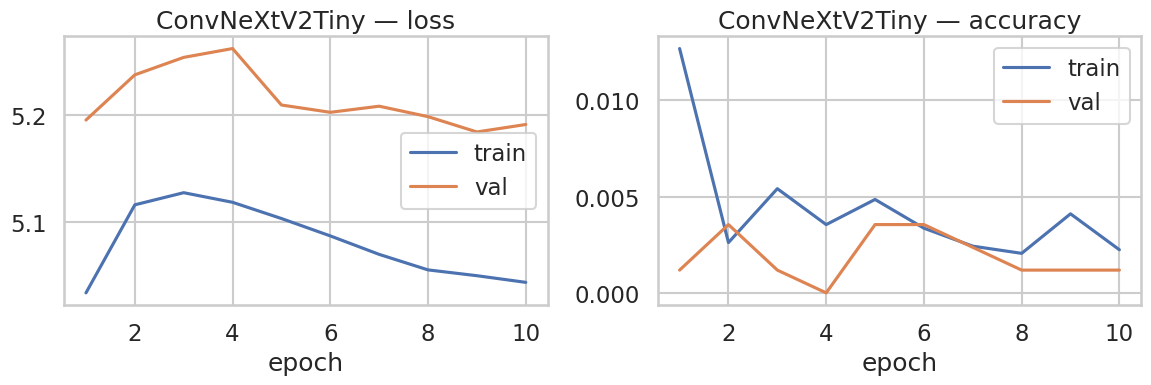

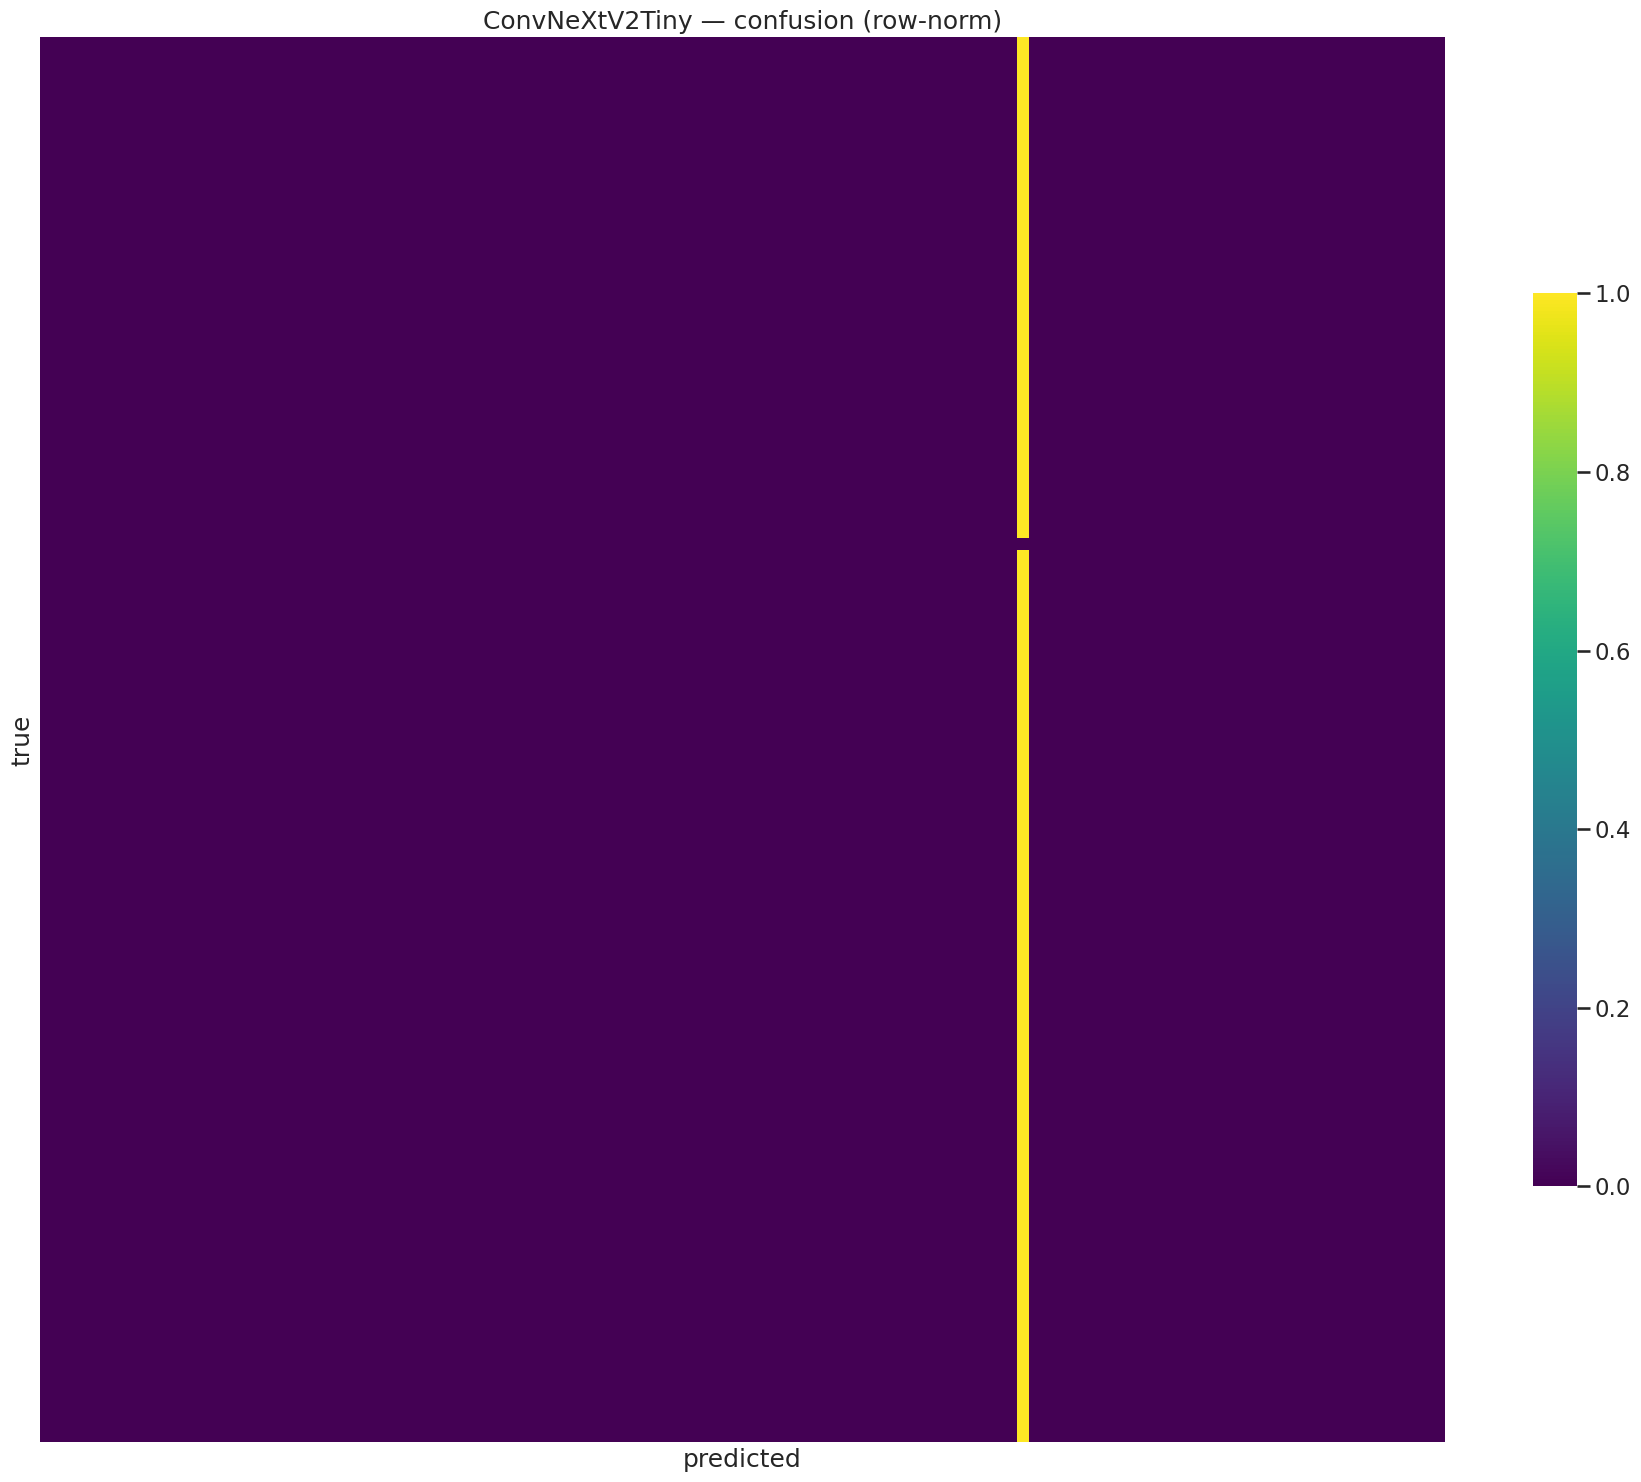

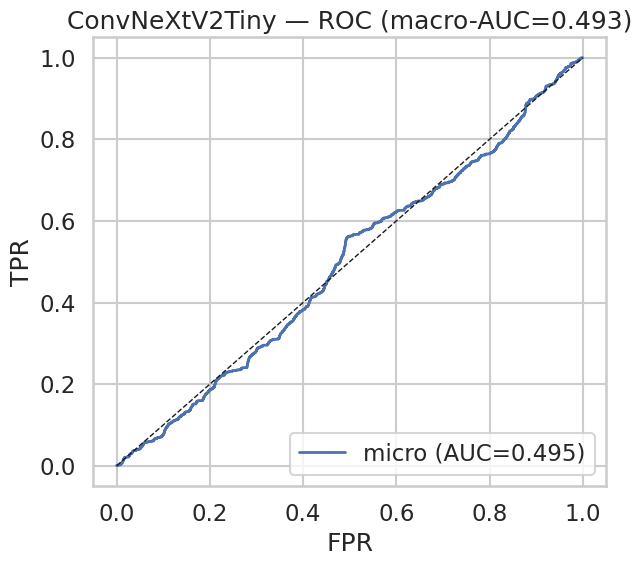

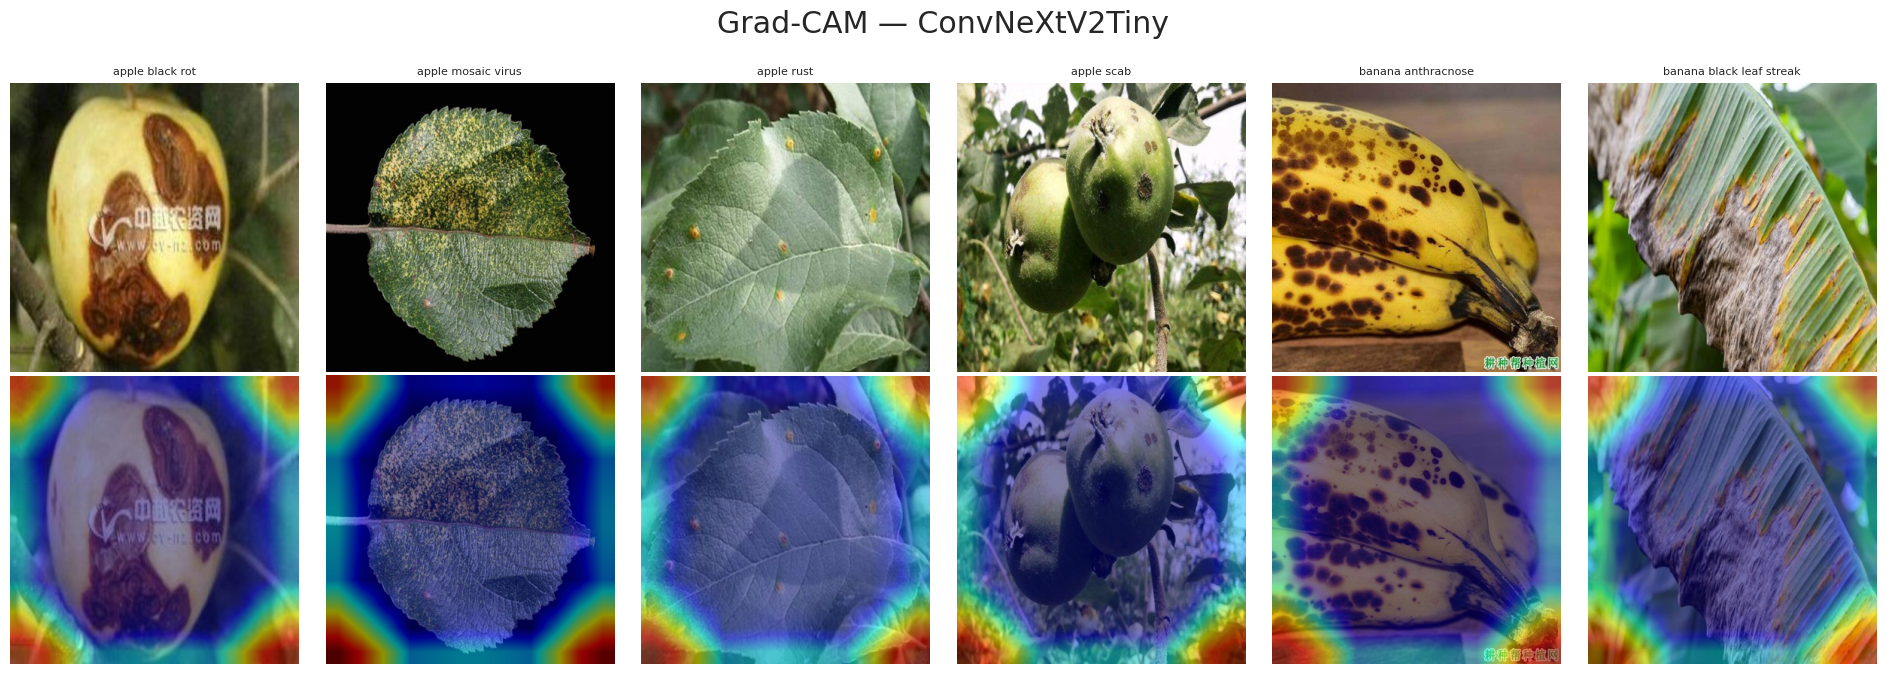


  Training: ViTBase16



model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

[ViTBase16] ep1/40 lr=2.0e-05 trL=4.756 vL=4.068 trA=0.070 vA=0.260
[ViTBase16] ep2/40 lr=3.5e-05 trL=2.750 vL=2.441 trA=0.474 vA=0.605
[ViTBase16] ep3/40 lr=5.0e-05 trL=1.878 vL=2.150 trA=0.668 vA=0.687
[ViTBase16] ep4/40 lr=5.0e-05 trL=1.620 vL=2.467 trA=0.738 vA=0.573
[ViTBase16] ep5/40 lr=5.0e-05 trL=1.423 vL=2.188 trA=0.795 vA=0.675
[ViTBase16] ep6/40 lr=4.9e-05 trL=1.323 vL=2.271 trA=0.837 vA=0.665
[ViTBase16] ep7/40 lr=4.9e-05 trL=1.240 vL=2.177 trA=0.868 vA=0.693
[ViTBase16] ep8/40 lr=4.8e-05 trL=1.158 vL=2.177 trA=0.895 vA=0.693
[ViTBase16] ep9/40 lr=4.7e-05 trL=1.141 vL=2.171 trA=0.892 vA=0.676
[ViTBase16] ep10/40 lr=4.6e-05 trL=1.102 vL=2.195 trA=0.915 vA=0.688
[ViTBase16] ep11/40 lr=4.4e-05 trL=1.068 vL=2.304 trA=0.920 vA=0.673
[ViTBase16] ep12/40 lr=4.3e-05 trL=1.038 vL=2.194 trA=0.934 vA=0.696
[ViTBase16] ep13/40 lr=4.2e-05 trL=1.040 vL=2.231 trA=0.931 vA=0.695
[ViTBase16] ep14/40 lr=4.0e-05 trL=1.023 vL=2.133 trA=0.939 vA=0.723
[ViTBase16] ep15/40 lr=3.8e-05 trL=0.989 vL

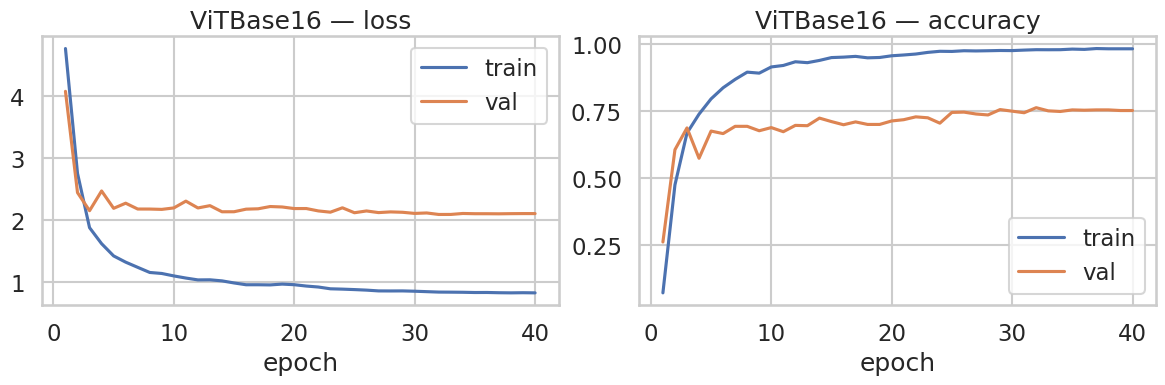

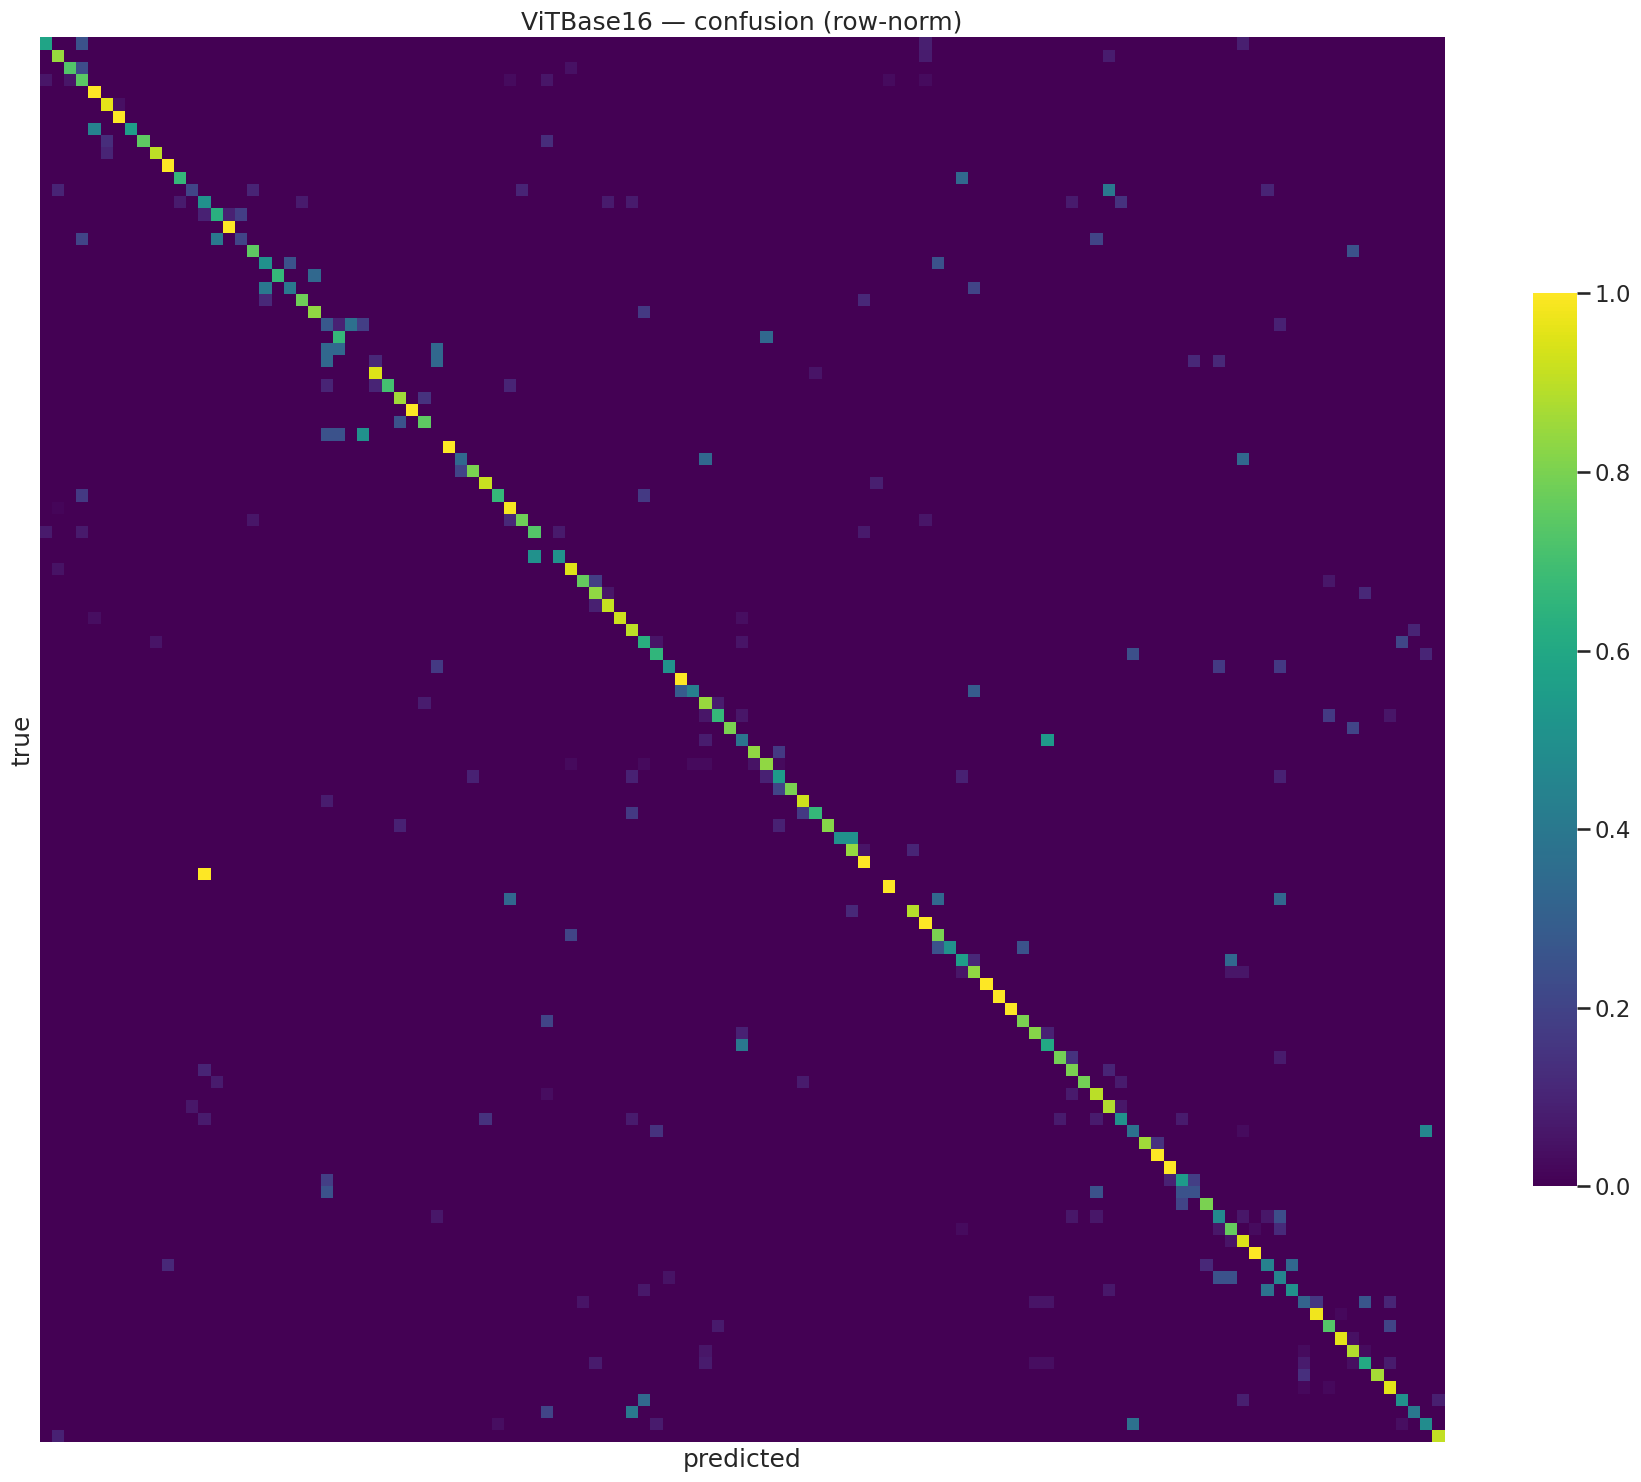

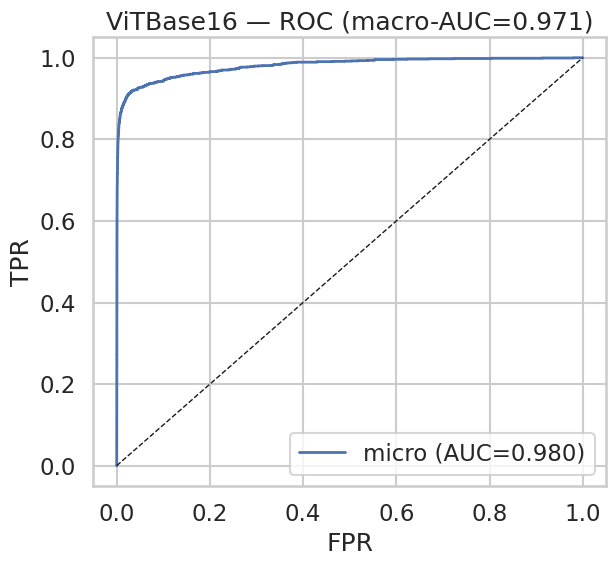

ViTBase16 is a transformer — Grad-CAM skipped (use attention rollout in Stage 4).

  Training: SwinTiny



model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

[SwinTiny] ep1/40 lr=2.0e-05 trL=4.981 vL=5.041 trA=0.024 vA=0.053
[SwinTiny] ep2/40 lr=3.5e-05 trL=4.074 vL=3.365 trA=0.208 vA=0.381
[SwinTiny] ep3/40 lr=5.0e-05 trL=2.727 vL=2.566 trA=0.475 vA=0.533
[SwinTiny] ep4/40 lr=5.0e-05 trL=2.164 vL=2.389 trA=0.604 vA=0.599
[SwinTiny] ep5/40 lr=5.0e-05 trL=1.836 vL=2.305 trA=0.681 vA=0.626
[SwinTiny] ep6/40 lr=4.9e-05 trL=1.624 vL=2.216 trA=0.754 vA=0.675
[SwinTiny] ep7/40 lr=4.9e-05 trL=1.471 vL=2.174 trA=0.798 vA=0.691
[SwinTiny] ep8/40 lr=4.8e-05 trL=1.379 vL=2.180 trA=0.823 vA=0.689
[SwinTiny] ep9/40 lr=4.7e-05 trL=1.290 vL=2.119 trA=0.857 vA=0.720
[SwinTiny] ep10/40 lr=4.6e-05 trL=1.263 vL=2.107 trA=0.865 vA=0.694
[SwinTiny] ep11/40 lr=4.4e-05 trL=1.237 vL=2.137 trA=0.875 vA=0.689
[SwinTiny] ep12/40 lr=4.3e-05 trL=1.186 vL=2.062 trA=0.892 vA=0.715
[SwinTiny] ep13/40 lr=4.2e-05 trL=1.150 vL=2.068 trA=0.899 vA=0.715
[SwinTiny] ep14/40 lr=4.0e-05 trL=1.109 vL=2.059 trA=0.914 vA=0.719
[SwinTiny] ep15/40 lr=3.8e-05 trL=1.101 vL=2.073 trA=0.91

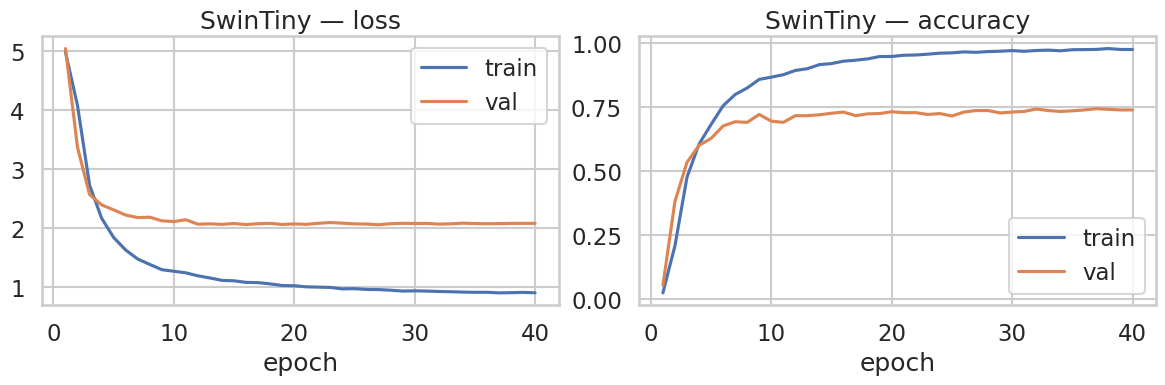

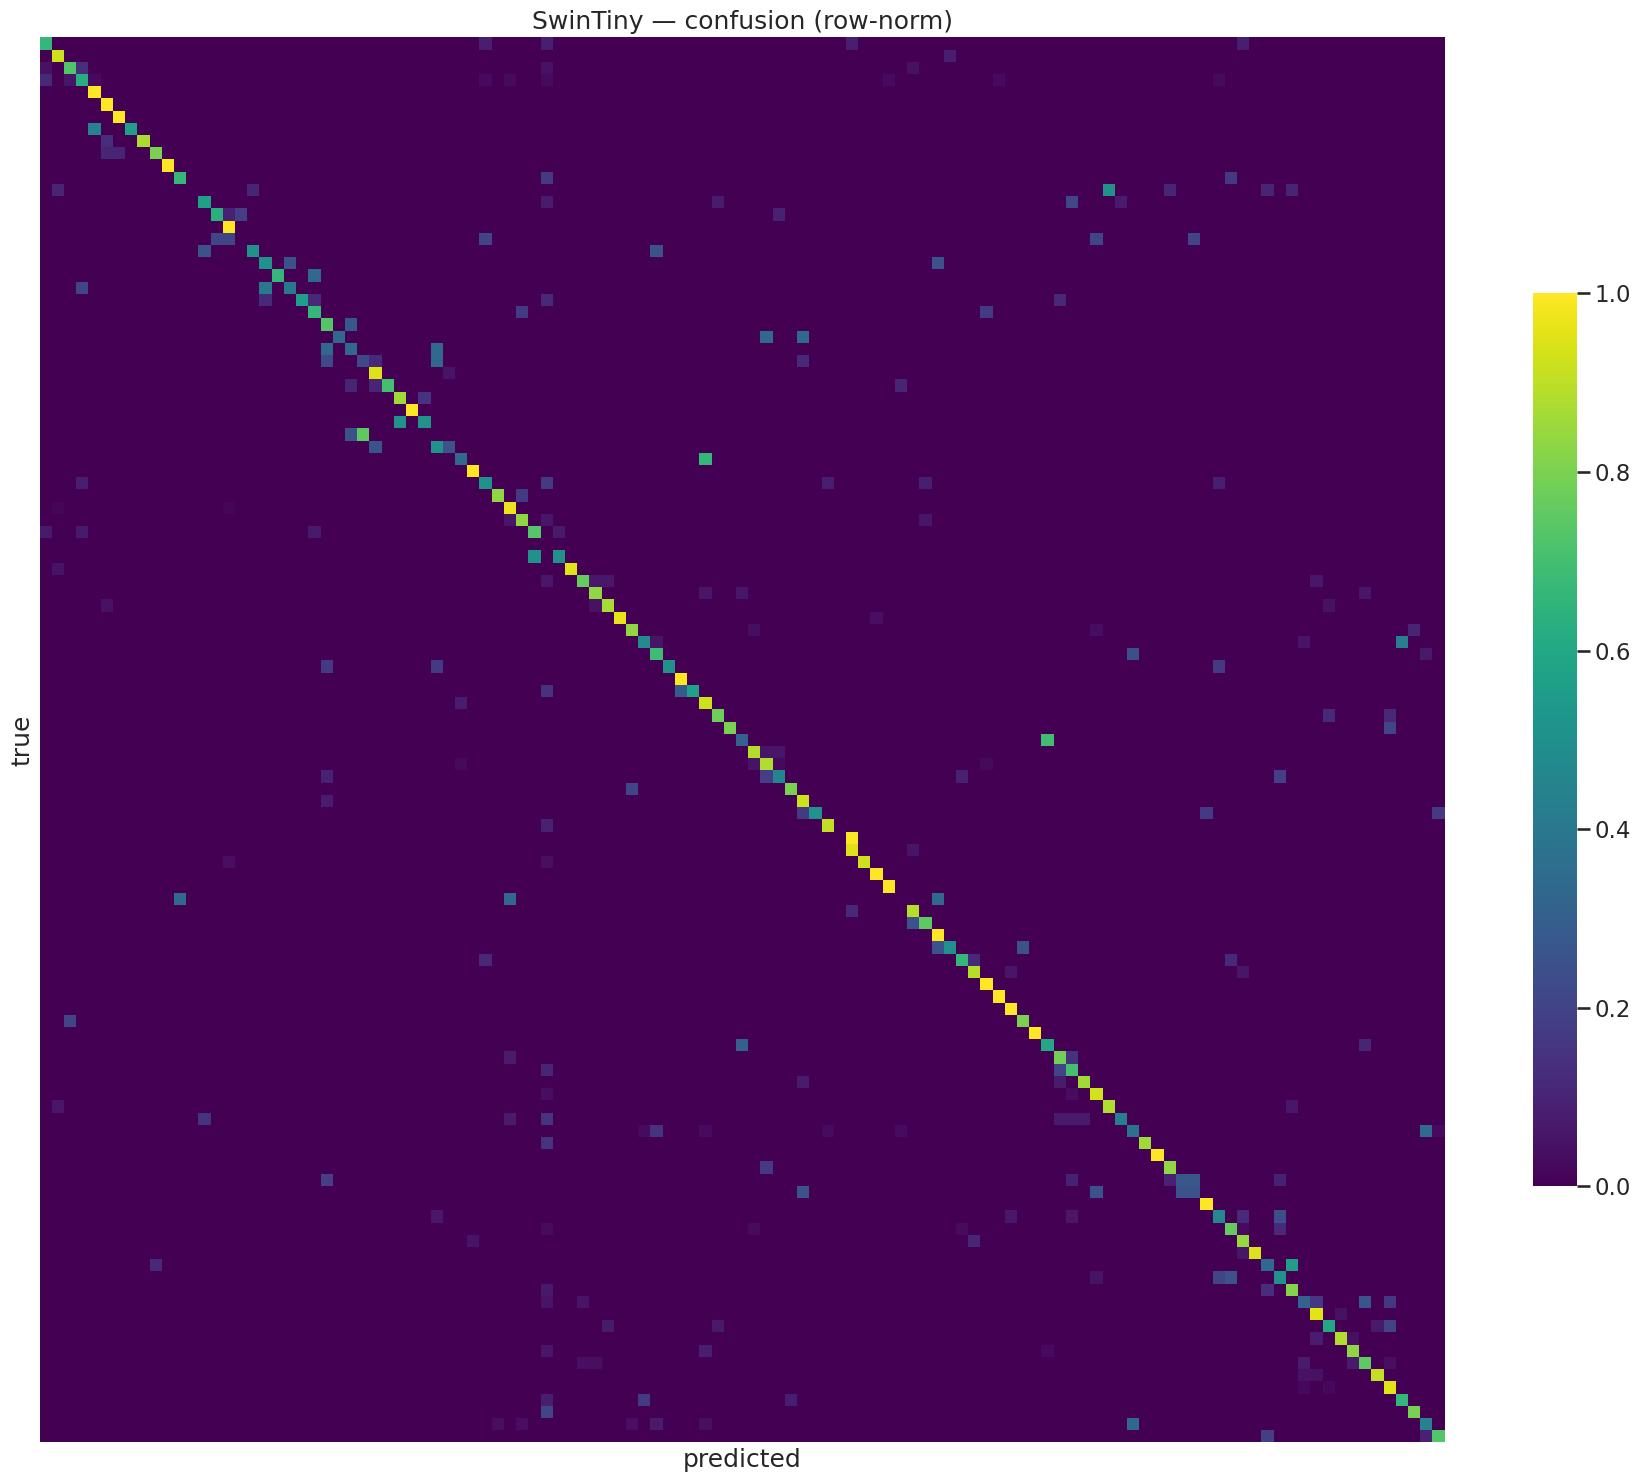

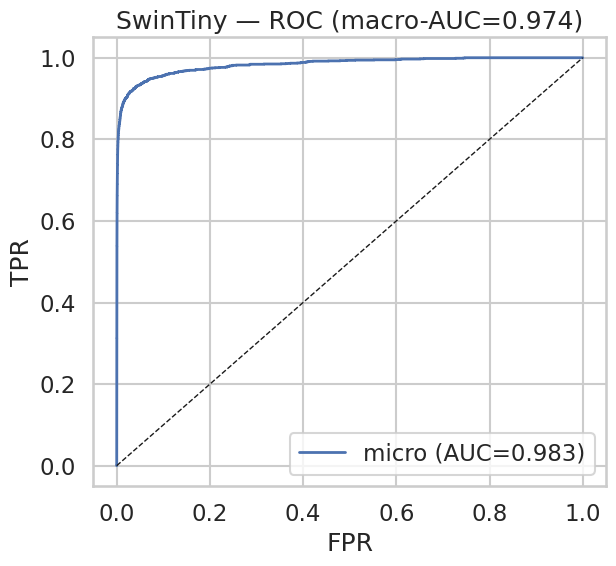

SwinTiny is a transformer — Grad-CAM skipped (use attention rollout in Stage 4).

  Training: GatedFusionLight

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 132MB/s] 


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

[GatedFusionLight] ep1/40 lr=1.6e-04 trL=4.992 vL=5.096 trA=0.028 vA=0.080
[GatedFusionLight] ep2/40 lr=3.0e-04 trL=4.230 vL=3.476 trA=0.151 vA=0.327
[GatedFusionLight] ep3/40 lr=3.0e-04 trL=3.484 vL=3.305 trA=0.267 vA=0.362
[GatedFusionLight] ep4/40 lr=3.0e-04 trL=2.961 vL=2.823 trA=0.395 vA=0.499
[GatedFusionLight] ep5/40 lr=3.0e-04 trL=2.521 vL=2.770 trA=0.493 vA=0.518
[GatedFusionLight] ep6/40 lr=2.9e-04 trL=2.273 vL=2.676 trA=0.541 vA=0.530
[GatedFusionLight] ep7/40 lr=2.9e-04 trL=2.086 vL=2.583 trA=0.590 vA=0.553
[GatedFusionLight] ep8/40 lr=2.8e-04 trL=1.960 vL=2.558 trA=0.623 vA=0.558
[GatedFusionLight] ep9/40 lr=2.8e-04 trL=1.867 vL=2.495 trA=0.652 vA=0.595
[GatedFusionLight] ep10/40 lr=2.7e-04 trL=1.721 vL=2.493 trA=0.693 vA=0.603
[GatedFusionLight] ep11/40 lr=2.6e-04 trL=1.604 vL=2.448 trA=0.731 vA=0.624
[GatedFusionLight] ep12/40 lr=2.5e-04 trL=1.563 vL=2.434 trA=0.744 vA=0.612
[GatedFusionLight] ep13/40 lr=2.4e-04 trL=1.480 vL=2.423 trA=0.776 vA=0.634
[GatedFusionLight] ep

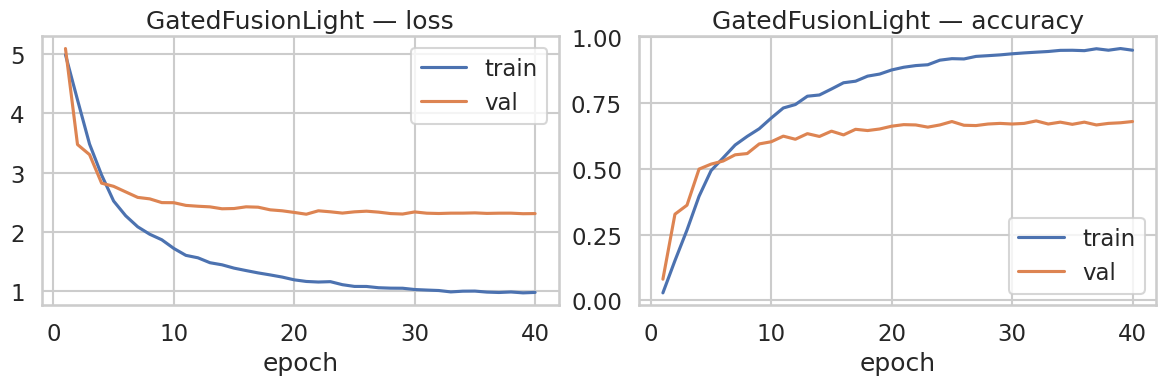

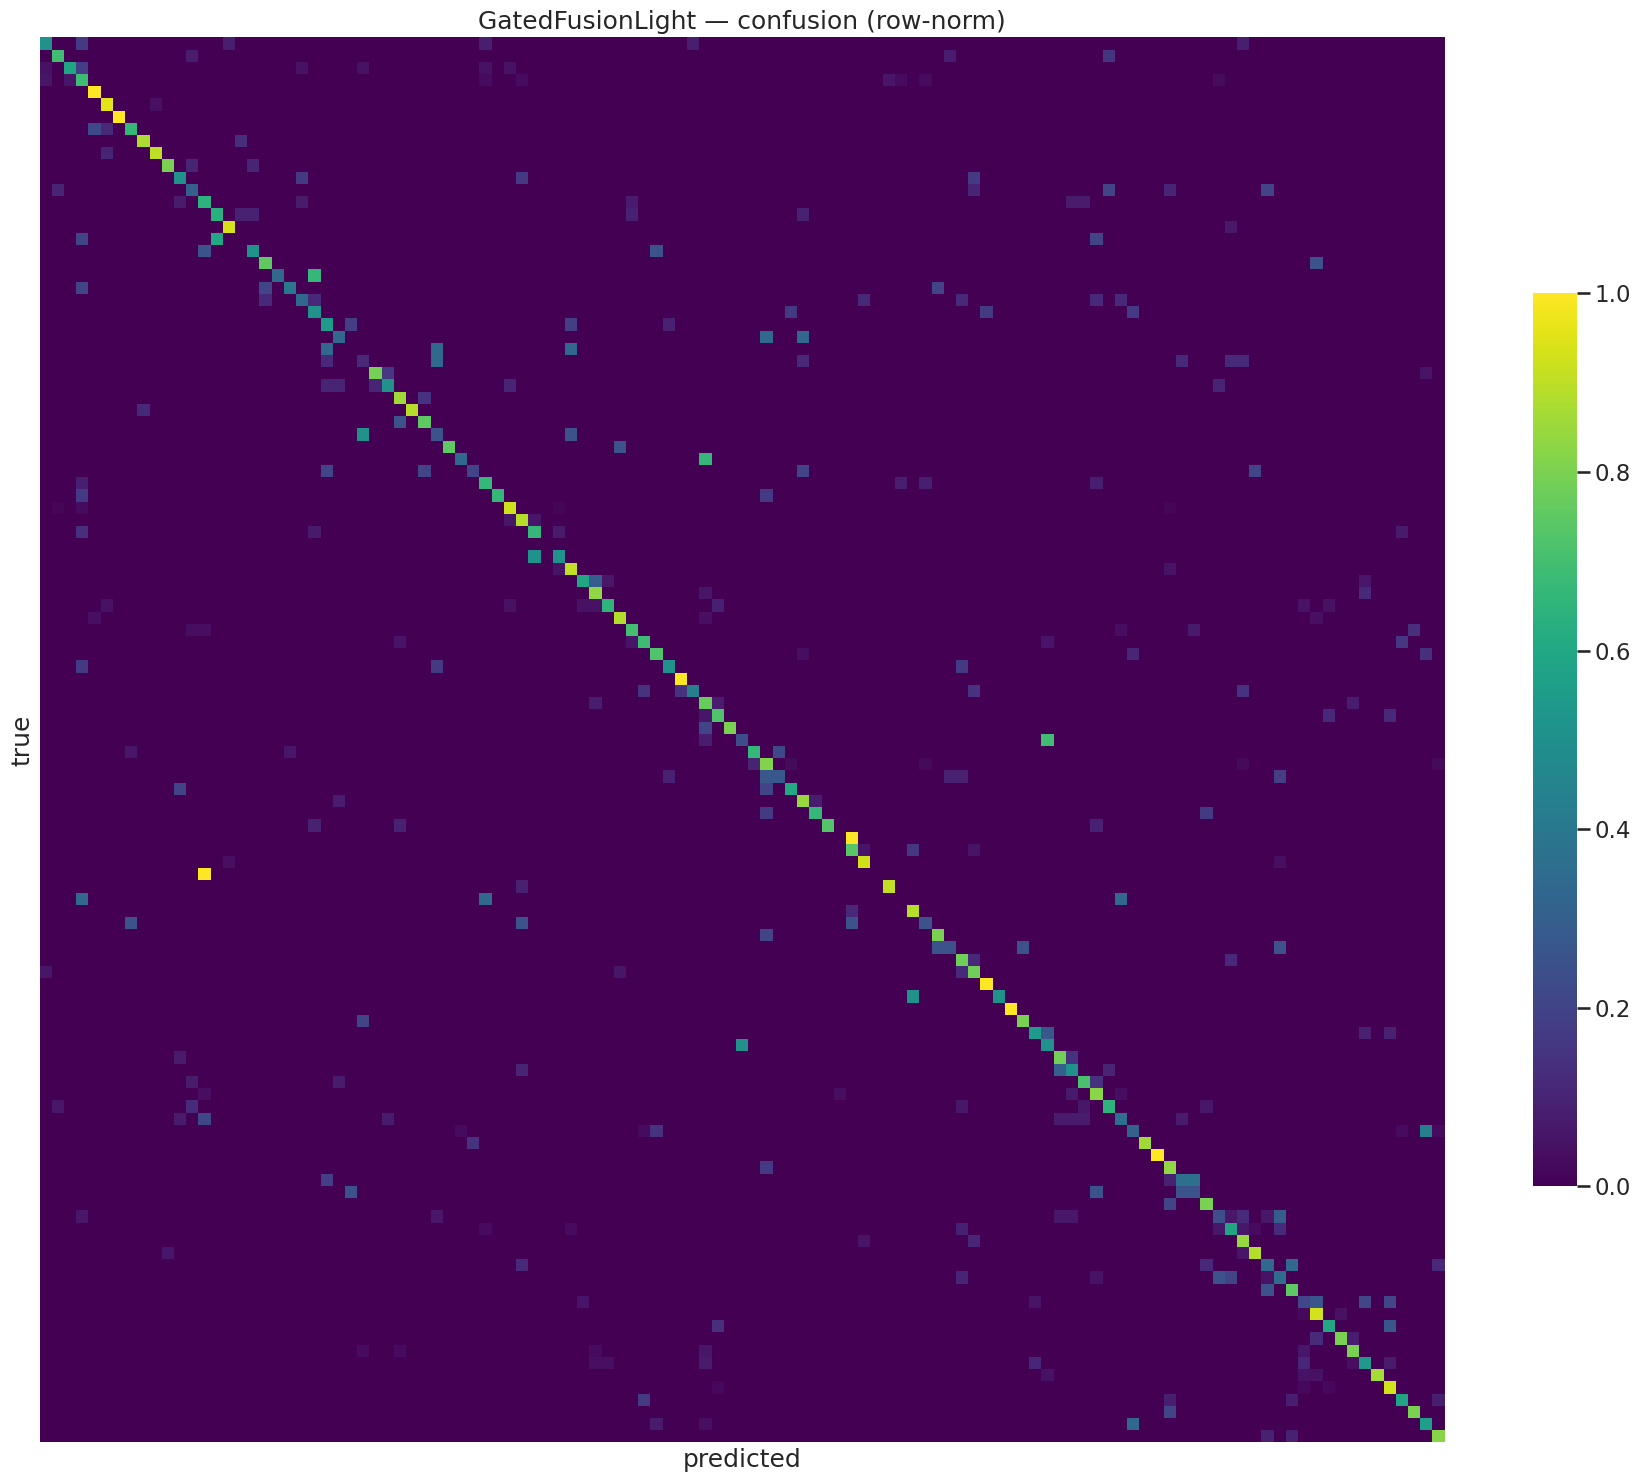

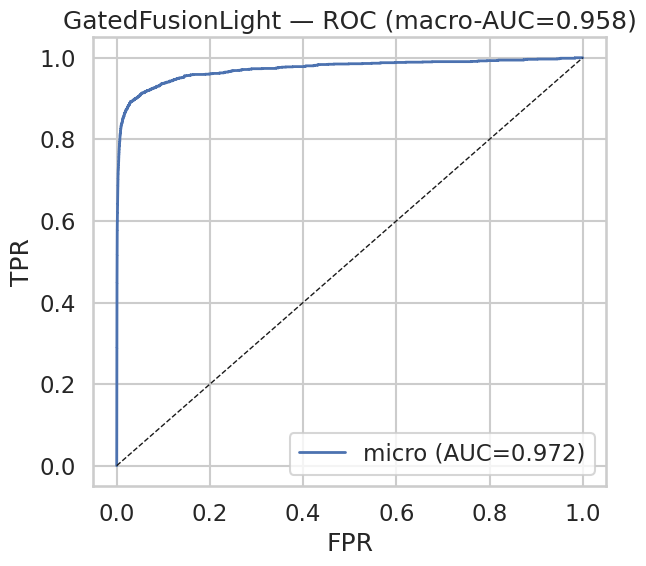

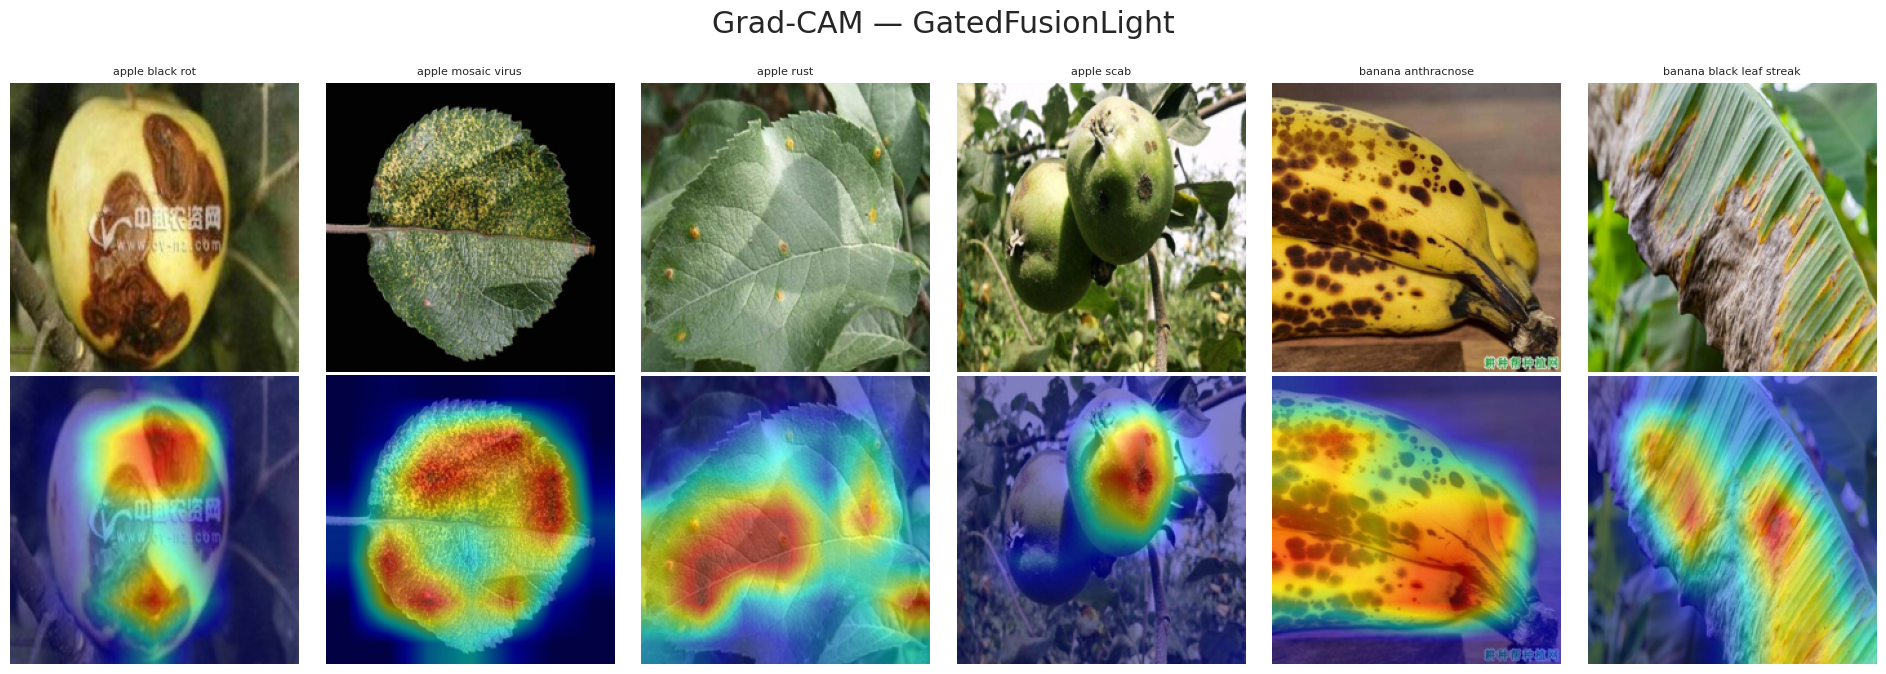


All models trained and saved.


In [9]:
# ============ MAIN LOOP — TRAIN ALL 8 MODELS ============
for MODEL_NAME in MODELS_TO_TRAIN[4:]:  # Session 2 — models 5–8
    print(f"\n{'='*60}")
    print(f"  Training: {MODEL_NAME}")
    print(f"{'='*60}\n")

    t0 = time.time()
    model, img_size, hist, Y, P, PR = train_one(MODEL_NAME)
    train_time = time.time()-t0

    metrics, cm = compute_metrics(Y, P, PR, NUM_CLASSES)
    dep = deployment(model, img_size)

    result = {
        "model_name": MODEL_NAME, "history": hist,
        "y_true": Y, "y_pred": P, "y_prob": PR,
        "metrics": metrics, "cm": cm, "deployment": dep,
        "img_size": img_size, "train_time_sec": train_time,
        "class_names": CLASS_NAMES,
    }
    pickle.dump(result, open(OUTDIR/f"result_{MODEL_NAME}.pkl","wb"))
    print("SAVED", OUTDIR/f"result_{MODEL_NAME}.pkl")
    print({k: round(v,4) for k,v in metrics.items() if isinstance(v, float)})
    print("deployment:", {k: round(v,2) for k,v in dep.items()})

    # Per-model plots
    plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size)

    # Grad-CAM
    plot_gradcam(MODEL_NAME, model, img_size)

print("\nAll models trained and saved.")
